# Time-Series Forecasting of Daily Revenue for an Online Retailer

## Problem Definition
The goal of this project is to forecast daily sales revenue for an online retailer.
Accurate short-term revenue forecasts help a business plan inventory, staffing and cash flow,
especially for a retailer whose customers are largely wholesalers placing large, irregular orders.

## Dataset
- **Source:** Online Retail dataset (UCI Machine Learning Repository / Kaggle), Chen et al. (2012)
- **Content:** ~540,000 individual transaction lines from 1 Dec 2010 to 9 Dec 2011
- **Columns:** InvoiceNo, StockCode, Description, Quantity, InvoiceDate, UnitPrice, CustomerID, Country

**Why this dataset?**
- It has a clear timestamp (`InvoiceDate`) and a meaningful target (revenue = Quantity × UnitPrice).
- Aggregating transactions by day produces several measurable variables over time
  (revenue, number of orders, number of customers, basket size, cancellation rate).
- Its natural structure (customers, products, invoices, invoice lines) supports a well-designed
  relational schema and MongoDB document model for the database tasks.
- It contains real-world data quality issues (missing customer IDs, cancellations, invalid prices),
  making preprocessing a meaningful part of the pipeline.

## Step 1: Load the data

In [34]:
!pip install ucimlrepo -q

import os
import pandas as pd
from ucimlrepo import fetch_ucirepo

os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

online_retail = fetch_ucirepo(id=352)
df = online_retail.data.original.copy()
df.to_csv("data/raw/online_retail_raw.csv", index=False)
print(df.shape, df.columns.tolist())

os.makedirs("outputs/figures", exist_ok=True)

(541909, 8) ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


## Step 2: Understanding the dataset

### 2.1 Structure & Data Types

This section inspects the dataset's size, columns and data types, converts each column to an
appropriate type, and counts the unique invoices, products, customers and countries.

In [35]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df["StockCode"] = df["StockCode"].astype(str)
df["CustomerID"] = df["CustomerID"].astype("Int64")  # keeps NaN, drops the ".0"
df.info()
display(df.head())
df[["InvoiceNo", "StockCode", "CustomerID", "Country"]].nunique()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  Int64         
 7   Country      541909 non-null  object        
dtypes: Int64(1), datetime64[ns](1), float64(1), int64(1), object(4)
memory usage: 33.6+ MB


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


,0
InvoiceNo,25900
StockCode,4070
CustomerID,4372
Country,38


**Observations:** The dataset contains 541,909 rows and 8 columns, where each row is a single product line within an invoice, so daily analysis will require aggregation. It covers 25,900 invoices, 4,070 products, 4,372 customers and 38 countries. `InvoiceDate` was converted to datetime, while `InvoiceNo`, `StockCode` and `CustomerID` were kept as categorical identifiers; `StockCode` must be text because codes such as `85123A` contain letters, despite the documentation. `Quantity` and `UnitPrice` are the only numerical columns, and revenue will be derived from them. Contrary to the UCI documentation, `CustomerID` (≈24.9%) and `Description` (≈0.3%) contain missing values.

### 2.2 Time Range & Granularity

This section identifies the period the data covers and how frequently transactions are recorded,
including which days of the week and hours of the day the shop trades.

In [36]:
start, end = df["InvoiceDate"].min(), df["InvoiceDate"].max()
print(f"From {start} to {end} ({(end - start).days} days)")
print("Days with transactions:", df["InvoiceDate"].dt.date.nunique())
print("\nTransactions by weekday:\n", df["InvoiceDate"].dt.day_name().value_counts())
print("\nTransactions by hour:\n", df["InvoiceDate"].dt.hour.value_counts().sort_index())

From 2010-12-01 08:26:00 to 2011-12-09 12:50:00 (373 days)
Days with transactions: 305

Transactions by weekday:
 InvoiceDate
Thursday     103857
Tuesday      101808
Monday        95111
Wednesday     94565
Friday        82193
Sunday        64375
Name: count, dtype: int64

Transactions by hour:
 InvoiceDate
6        41
7       383
8      8909
9     34332
10    49037
11    57674
12    78709
13    72259
14    67471
15    77519
16    54516
17    28509
18     7974
19     3705
20      871
Name: count, dtype: int64


**Observations:** The data runs from 1 December 2010 to 9 December 2011, just over one year, so only one yearly cycle is available. Transactions occur on 305 of 374 calendar days: the shop never trades on Saturdays, and the remaining gaps are likely the Christmas closure and bank holidays. These are closures, not missing data, so they will not be filled. Activity peaks on Thursdays and Tuesdays and is lowest on Sundays, suggesting a weekly pattern. Trading happens between 06:00 and 20:00, with about 84% between 10:00 and 16:00. Because the raw timestamps are irregular and concentrated in business hours, the data will be aggregated to a daily series. The final day ends at midday, so the last week is incomplete.

### 2.3 Missing Values & Data Quality

This section quantifies missing values and other data quality issues (duplicates, cancellations,
negative quantities, invalid prices and non product codes). These are only identified here;
how each is handled is decided in Step 3.

In [37]:
missing = pd.DataFrame({"missing": df.isna().sum(),
                        "percent": (df.isna().mean() * 100).round(2)})
display(missing[missing["missing"] > 0])

print("Duplicate rows:", df.duplicated().sum())
print("Cancelled invoice lines:", df["InvoiceNo"].str.startswith("C").sum())
print("Negative quantity:", (df["Quantity"] < 0).sum())
print("Zero/negative price:", (df["UnitPrice"] <= 0).sum())
print("\nNon-product codes:\n", df[~df["StockCode"].str.match(r"^\d{5}")]["StockCode"].value_counts().head(15))

,missing,percent
Description,1454,0.27
CustomerID,135080,24.93


Duplicate rows: 5268
Cancelled invoice lines: 9288
Negative quantity: 10624
Zero/negative price: 2517

Non-product codes:
 StockCode
POST            1256
DOT              710
M                571
C2               144
D                 77
S                 63
BANK CHARGES      37
AMAZONFEE         34
CRUK              16
DCGSSGIRL         13
DCGSSBOY          11
gift_0001_20      10
gift_0001_10       9
gift_0001_30       8
DCGS0003           5
Name: count, dtype: int64


**Observations:** `Description` is missing in 1,454 rows (0.27%), which is negligible, but `CustomerID` is missing in 135,080 rows (24.93%). Since these are still real sales, dropping them would remove about a quarter of revenue. The data also contains 5,268 duplicate rows, 9,288 cancelled invoice lines, 10,624 negative quantities (so 1,336 are adjustments rather than cancellations) and 2,517 zero or negative prices. Several stock codes represent postage, fees, discounts, samples and gift vouchers rather than products, and would distort a sales forecast. Some unusual codes, such as `DCGSSGIRL`, are genuine products, so non-products will be removed using an explicit list rather than pattern matching. Each issue is handled in Step 3.

### 2.4 Distributions
This section examines the statistical distribution of the numerical columns (Quantity and
UnitPrice) and the spread of transactions across countries, to understand skew, outliers and
which markets dominate the data.

,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


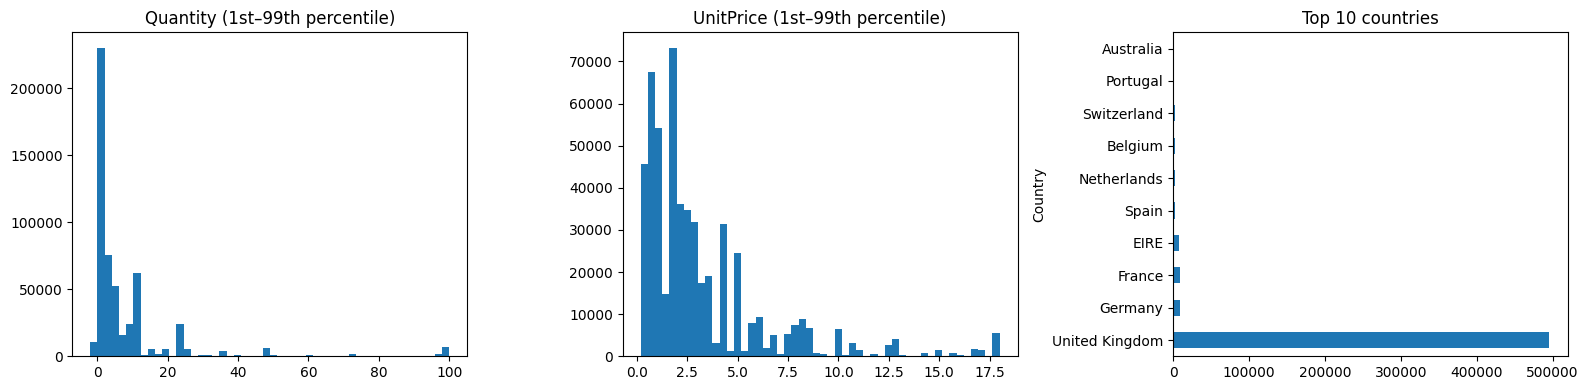

In [38]:
display(df[["Quantity", "UnitPrice"]].describe())

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes[:2], ["Quantity", "UnitPrice"]):
    clipped = df[col].clip(df[col].quantile(0.01), df[col].quantile(0.99))
    ax.hist(clipped, bins=50); ax.set_title(f"{col} (1st–99th percentile)")
df["Country"].value_counts().head(10).plot.barh(ax=axes[2], title="Top 10 countries")
plt.tight_layout(); plt.savefig("outputs/figures/distributions.png"); plt.show()

**Observations:** Both numerical columns are heavily right-skewed with extreme outliers. For `Quantity`, the median line is 3 units and 75% of lines are 10 units or fewer, yet the standard deviation is 218, and the mirrored extremes (−80,995 and +80,995) suggest a very large order that was entered and then cancelled. The clipped histogram shows clear spikes at 12, 24, 48 and 100 units, indicating that many items are sold in fixed pack sizes, consistent with wholesale customers. `UnitPrice` has a median of £2.08, and 75% of items cost £4.13 or less, confirming that the shop sells mainly low-cost gifts, while its extremes (−£11,062.06 and £38,970) are likely accounting adjustments rather than real products. The price histogram also shows spikes at common retail price points rather than a smooth spread. Geographically, the United Kingdom accounts for about 495,000 transaction lines (≈91%), followed distantly by Germany, France and EIRE, so the revenue series will mainly reflect UK demand. Most of the extreme values belong to the issues identified in Section 2.3 and are expected to disappear after cleaning.

### Summary
- **Time range:** 1 December 2010 to 9 December 2011, just over one year (374 calendar days, 305 trading days).
- **Granularity:** One row per product line within an invoice, with minute-level timestamps at irregular intervals. The data is aggregated to a daily series in Step 4.
- **Missing values:** Despite the documentation, `CustomerID` is missing in 24.93% of rows and `Description` in 0.27%. The 69 days without transactions are closures (Saturdays and UK holidays), not missing data.
- **Distributions:** `Quantity` and `UnitPrice` are heavily right-skewed with extreme outliers: most lines are a few low-cost items, but rare very large orders and adjustments create extreme values.
- **Data quality issues:** 5,268 duplicate rows, 9,288 cancelled lines, 10,624 negative quantities, 2,517 zero or negative prices, and several non-product codes (postage, fees, discounts, vouchers). All are handled in Step 3.

## Step 3: Data Cleaning
This step resolves the data quality issues identified in Section 2.3. Each cleaning decision is
justified and logged, so the number of rows removed at every step is visible.

### 3.1 Identifying Non-Product Codes
Before removing anything, all stock codes that do not follow the standard 5-digit product format
are listed with their descriptions, to separate genuine products from postage, fees and adjustments.

In [39]:
odd = df[~df["StockCode"].str.match(r"^\d{5}")]
(odd.groupby("StockCode")["Description"]
    .agg(lambda s: s.dropna().unique()[:2])
    .to_frame()
    .assign(rows=odd["StockCode"].value_counts()))

,Description,rows
StockCode,,
AMAZONFEE,[AMAZON FEE],34
B,[Adjust bad debt],3
BANK CHARGES,[Bank Charges],37
C2,[CARRIAGE],144
CRUK,[CRUK Commission],16
D,[Discount],77
DCGS0003,"[BOXED GLASS ASHTRAY, ebay]",5
DCGS0004,[HAYNES CAMPER SHOULDER BAG],1
DCGS0055,[],1


**Observations:** Listing every non-standard stock code with its description shows that they fall into two groups. The first group is not product sales: postage and carriage (`POST`, `DOT`, `C2`), manual entries (`M` and lowercase `m`), discounts (`D`), samples (`S`), bad-debt adjustments (`B`), bank and marketplace fees (`BANK CHARGES`, `AMAZONFEE`), charity commission (`CRUK`) and gift vouchers (`gift_0001_*`). These represent services, fees, adjustments or prepaid credit rather than demand for products, so they will be removed. The second group consists of genuine products with non-standard codes, including the `DCGS` codes (e.g. a boxed glass ashtray, dog collars, party bags and a night light) and `PADS` (cushion pads), which will be kept. Some `DCGS` rows have an empty description or only "ebay", suggesting stock adjustments rather than real sales; these are expected to be removed by the zero-price filter, which is verified in Section 3.3. This inspection confirms that non-products must be removed using an explicit, case-insensitive list, since a pattern-based rule would wrongly delete genuine products.

### 3.2 Cleaning Pipeline
The cleaning steps are applied in a fixed order and wrapped in a function, so they can be reused
in Task 4. A log records how many rows each step removes.

In [40]:
NON_PRODUCT_CODES = ["POST", "DOT", "C2", "M", "D", "S", "B", "BANK CHARGES",
                     "AMAZONFEE", "CRUK"]

def clean_transactions(df):
    df = df.copy()
    log = [("Raw data", len(df))]

    # 1. Exact duplicates would double-count revenue
    df = df.drop_duplicates()
    log.append(("Remove exact duplicates", len(df)))

    # 2. Postage, fees, discounts, adjustments and gift vouchers are not product demand
    df = df[~df["StockCode"].str.upper().isin(NON_PRODUCT_CODES)]
    df = df[~df["StockCode"].str.lower().str.startswith("gift_")]
    log.append(("Remove non-product codes", len(df)))

    # 3. Zero or negative prices are not genuine sales
    df = df[df["UnitPrice"] > 0]
    log.append(("Remove zero/negative prices", len(df)))

    # 4. Keep cancellations (flagged); drop other negative quantities (stock adjustments)
    df["is_cancelled"] = df["InvoiceNo"].str.startswith("C")
    df = df[(df["Quantity"] > 0) | df["is_cancelled"]]
    log.append(("Remove non-cancelled negative quantities", len(df)))

    # 5. Keep sales with unknown customers; fill ID so database foreign keys stay valid
    df["CustomerID"] = df["CustomerID"].astype("string").fillna("UNKNOWN")
    df["Description"] = df["Description"].str.strip()
    df["Revenue"] = df["Quantity"] * df["UnitPrice"]

    log = pd.DataFrame(log, columns=["step", "rows_remaining"])
    log["rows_removed"] = (log["rows_remaining"].shift(1) - log["rows_remaining"]).fillna(0).astype(int)
    return df, log

clean_df, cleaning_log = clean_transactions(df)
display(cleaning_log)

,step,rows_remaining,rows_removed
0,Raw data,541909,0
1,Remove exact duplicates,536641,5268
2,Remove non-product codes,533701,2940
3,Remove zero/negative prices,531208,2493
4,Remove non-cancelled negative quantities,531208,0


**Observations:** Cleaning reduced the dataset from 541,909 to 531,208 rows, removing 10,701 rows (about 2.0%) in total. This shows that the quality issues, while important, affect only a small share of the data. Removing exact duplicates accounted for the largest share (5,268 rows), followed by non-product codes (2,940 rows) and zero or negative prices (2,493 rows). The price filter removed slightly fewer rows than the 2,517 counted in Section 2.3 because some of those rows had already been removed as duplicates or non-product codes, such as the negative-price bad-debt adjustments (`B`). Notably, the final step removed no rows: all 1,336 negative-quantity rows that were not cancellations also had a zero price and were already removed by the price filter. This supports the earlier interpretation that these rows were stock adjustments rather than real customer returns. The step is kept in the pipeline as a safeguard, so the cleaning remains correct if new data passed through the function in Task 4 behaves differently. All 9,288 cancelled lines (minus any duplicates) are retained and flagged, and rows with missing customer IDs are kept as `UNKNOWN`, preserving real sales revenue.

### 3.3 Verification and Export
The cleaned data is checked to confirm the issues from Section 2.3 are resolved, then saved
for use by the database team.

In [41]:
print("Remaining missing values:\n", clean_df.isna().sum()[clean_df.isna().sum() > 0])
print("Duplicates:", clean_df.duplicated().sum())
print("Min price:", clean_df["UnitPrice"].min())
print("Cancelled lines kept:", clean_df["is_cancelled"].sum())
print("Rows with UNKNOWN customer:", (clean_df["CustomerID"] == "UNKNOWN").sum())
display(clean_df[["Quantity", "UnitPrice", "Revenue"]].describe())

clean_df.to_csv("data/processed/transactions_clean.csv", index=False)
print("Saved:", clean_df.shape)

Remaining missing values:
 Series([], dtype: int64)
Duplicates: 0
Min price: 0.001
Cancelled lines kept: 8668
Rows with UNKNOWN customer: 131549


,Quantity,UnitPrice,Revenue
count,531208.000000,531208.000000,531208.000000
mean,9.961013,3.292615,18.394524
std,217.007170,4.512931,369.755065
min,-80995.000000,0.001000,-168469.600000
25%,1.000000,1.250000,3.750000
50%,3.000000,2.080000,9.900000
75%,10.000000,4.130000,17.400000
max,80995.000000,649.500000,168469.600000


Saved: (531208, 10)


**Observations:** The verification confirms that the cleaning resolved the issues identified in Section 2.3. No missing values remain: the 1,454 rows with no `Description` all had a zero price and were removed by the price filter, while the missing customer IDs are now labelled `UNKNOWN` (131,549 rows, about 24.8% of the cleaned data). No duplicates remain, and the minimum unit price is now £0.001, a genuine low-value item (cushion pads) rather than an adjustment. 8,668 cancelled lines are retained and flagged; the difference from the 9,288 counted earlier comes from cancellations that were duplicates or

**Checking extreme orders:** The ±80,995 quantities above suggest very large orders that were later
cancelled. The rows below list all transactions of 70,000 units or more, to confirm whether each
order and its cancellation fall on the same day before choosing how to define daily revenue.

In [42]:
clean_df[clean_df["Quantity"].abs() >= 70000][
    ["InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate", "CustomerID"]
]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,CustomerID
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,12346
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,12346
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,16446
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,16446


**Observations:** Only two orders exceed 70,000 units, and both were cancelled almost immediately. Customer 12346 ordered 74,215 medium ceramic storage jars on 18 January 2011 at 10:01 and cancelled 16 minutes later, while customer 16446 ordered 80,995 "Little Birdie" paper craft items on 9 December 2011 at 09:15 and cancelled 12 minutes later. Each cancellation matches its original order exactly in customer, product and quantity, so these were most likely data-entry errors rather than real purchases. If daily revenue counted only sales, these two orders would create artificial spikes of roughly £77,000 and £168,000 on days when no such sales actually happened. For this reason, the

## Step 4: Aggregating to a Daily Time Series
The cleaned transactions are aggregated into one row per trading day. The forecasting target is
**daily net revenue** (sales minus cancellations), justified in Section 3.3. Several additional daily
variables are created to describe customer activity, so the series contains multiple measurable
variables over time.

### 4.1 Daily Aggregation

In [43]:
def aggregate_daily(df):
    df = df.copy()
    df["date"] = df["InvoiceDate"].dt.normalize()
    sales = df[~df["is_cancelled"]]

    # Activity measures use completed sales only
    daily = sales.groupby("date").agg(
        gross_revenue=("Revenue", "sum"),
        n_invoices=("InvoiceNo", "nunique"),
        n_products=("StockCode", "nunique"),
        total_quantity=("Quantity", "sum"),
    )
    # Count known customers only, so "UNKNOWN" isn't treated as one customer
    known = sales[sales["CustomerID"] != "UNKNOWN"]
    daily["n_customers"] = known.groupby("date")["CustomerID"].nunique()

    # Target: net revenue includes cancellations (negative revenue)
    daily["net_revenue"] = df.groupby("date")["Revenue"].sum()
    daily["cancel_rate"] = df.groupby("date")["is_cancelled"].mean()
    daily["avg_basket"] = daily["gross_revenue"] / daily["n_invoices"]
    uk = sales[sales["Country"] == "United Kingdom"].groupby("date")["Revenue"].sum()
    daily["uk_share"] = uk / daily["gross_revenue"]
    return daily.fillna(0)

daily = aggregate_daily(clean_df)
print(daily.shape)
display(daily.head())

(305, 9)


,gross_revenue,n_invoices,n_products,total_quantity,n_customers,net_revenue,cancel_rate,avg_basket,uk_share
date,,,,,,,,,
2010-12-01,57442.33,127,1336,26808,95,57144.60,0.008210,452.301811,0.930266
2010-12-02,47596.42,141,921,31262,98,46055.32,0.021318,337.563262,0.996642
2010-12-03,44788.90,68,1130,16136,50,43465.65,0.006551,658.660294,0.881868
2010-12-05,30908.67,88,1140,16163,75,30546.96,0.005756,351.234886,0.821806
2010-12-06,51667.12,102,1467,21592,82,50701.25,0.012615,506.540392,0.973632


**Observations:** Aggregation produced 305 daily rows with 9 variables. Net revenue is slightly below gross revenue because of cancellations, and daily invoices, customers and products vary considerably from day to day. Invoices exceed customers because some customers order several times a day and unknown customers are not counted. High average basket values reflect the wholesale customer base, and the UK generates most of the revenue. These variables give the series several measurable dimensions beyond revenue.

### 4.2 Checking Calendar Gaps
Days with no transactions are identified to confirm they are closures (Saturdays and holidays)
rather than missing data.

In [44]:
full_range = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
missing_days = full_range.difference(daily.index)
print("Calendar days:", len(full_range), "| Trading days:", len(daily), "| No-trade days:", len(missing_days))
print(pd.Series(missing_days.day_name()).value_counts())
print("\nNon-Saturday gaps:\n", missing_days[missing_days.dayofweek != 5].date)

Calendar days: 374 | Trading days: 305 | No-trade days: 69
Saturday     53
Monday        6
Friday        4
Sunday        3
Tuesday       1
Wednesday     1
Thursday      1
Name: count, dtype: int64

Non-Saturday gaps:
 [datetime.date(2010, 12, 24) datetime.date(2010, 12, 26)
 datetime.date(2010, 12, 27) datetime.date(2010, 12, 28)
 datetime.date(2010, 12, 29) datetime.date(2010, 12, 30)
 datetime.date(2010, 12, 31) datetime.date(2011, 1, 2)
 datetime.date(2011, 1, 3) datetime.date(2011, 4, 22)
 datetime.date(2011, 4, 24) datetime.date(2011, 4, 25)
 datetime.date(2011, 4, 29) datetime.date(2011, 5, 2)
 datetime.date(2011, 5, 30) datetime.date(2011, 8, 29)]


**Observations:** Of 374 calendar days, 305 are trading days. The 69 non-trading days are 53 Saturdays plus 16 UK closures: the Christmas shutdown (24 December 2010 to 3 January 2011), Easter, the Royal Wedding bank holiday and the May, Spring and Summer bank holidays. Since every gap is a closure, no imputation is needed; filling these days would invent activity that never happened. As a result, a one-row lag means "the previous trading day", which may be several calendar days earlier after a weekend or holiday.

### 4.3 Final Daily Series
The last day (9 December 2011) ends at midday, so it is removed to avoid an artificially low final value.

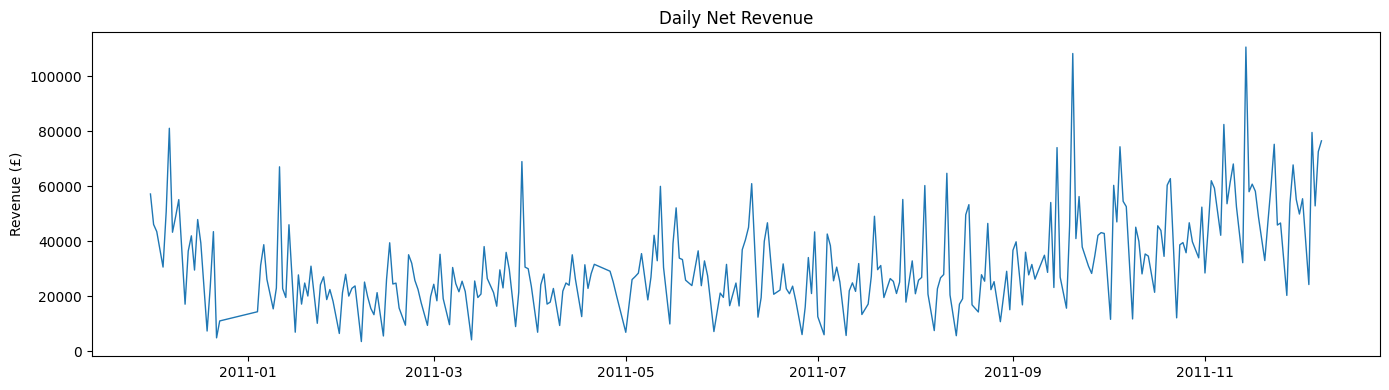

,gross_revenue,n_invoices,n_products,total_quantity,n_customers,net_revenue,cancel_rate,avg_basket,uk_share
count,304.00,304.00,304.00,304.00,304.00,304.00,304.00,304.00,304.00
mean,33056.33,64.90,902.12,17985.03,54.75,32045.35,0.02,501.48,0.86
std,18037.81,25.16,267.52,9672.06,21.40,17389.96,0.01,209.22,0.12
min,3439.67,11.00,191.00,2036.00,11.00,3439.67,0.00,228.07,0.36
25%,21495.79,49.00,733.75,11735.00,40.00,20832.85,0.01,376.29,0.81
50%,28480.34,62.50,865.00,16114.00,52.00,27802.40,0.01,452.75,0.89
75%,44048.77,76.00,1049.50,22129.75,65.00,41960.52,0.02,563.25,0.94
max,111348.61,141.00,1763.00,82921.00,125.00,110623.68,0.09,2359.11,1.00


Saved: (304, 9)


In [45]:
daily = daily[daily.index < "2011-12-09"]

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily.index, daily["net_revenue"], linewidth=1)
ax.set_title("Daily Net Revenue"); ax.set_ylabel("Revenue (£)")
plt.tight_layout(); plt.savefig("outputs/figures/daily_net_revenue.png"); plt.show()

display(daily.describe().round(2))
daily.to_csv("data/processed/daily_series.csv")
print("Saved:", daily.shape)

**Observations:** After removing the incomplete final day, the series contains 304 trading days. Daily net revenue averages £32,045 (median £27,802) and ranges from £3,440 to £110,624, so it is right-skewed and highly variable. Cancellations reduce revenue by about 3% on average. Revenue stays mostly between £10,000 and £40,000 from January to August, then rises sharply from September towards Christmas, although one year of data cannot confirm this as a repeating annual pattern. The straight line in late December is the Christmas shutdown. Because the final months are higher than the rest of the year, a chronological test set will cover a peak the model has not seen in training.

## Step 5: Analytical Questions
This step answers six analytical questions about the daily series. Each question is answered
with at least one visualization and an interpretation. Questions 1 and 2 use moving averages
and lagged features to study the trend and the dependence of revenue on its own past values.

### Q1: Is daily net revenue increasing over time?
A 7-day and a 30-day moving average are plotted over the daily series to smooth out day-to-day
noise and reveal the underlying trend. Time-based windows ("7D", "30D") are used so that each
average covers a fixed calendar period, even across closures.

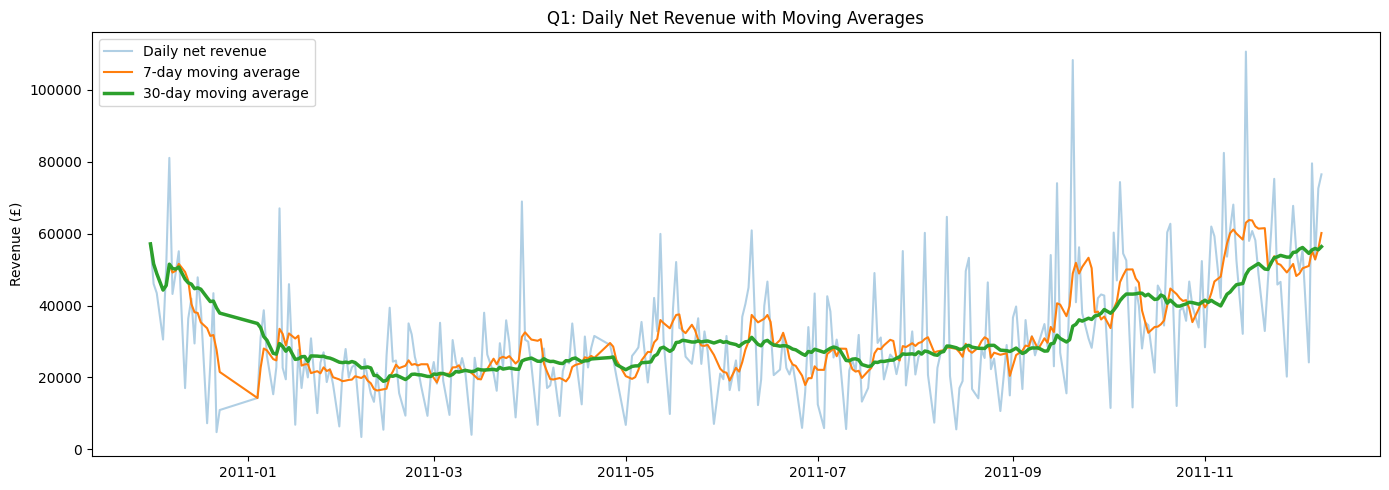

,avg_daily_net_revenue
date,
Dec 2010,37905.0
Jan 2011,24119.0
Feb 2011,20811.0
Mar 2011,25160.0
Apr 2011,22955.0
May 2011,29240.0
Jun 2011,27840.0
Jul 2011,26031.0
Aug 2011,26973.0


In [46]:
rev = daily["net_revenue"]
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(rev.index, rev, alpha=0.35, label="Daily net revenue")
ax.plot(rev.index, rev.rolling("7D").mean(), label="7-day moving average")
ax.plot(rev.index, rev.rolling("30D").mean(), linewidth=2.5, label="30-day moving average")
ax.set_title("Q1: Daily Net Revenue with Moving Averages"); ax.set_ylabel("Revenue (£)"); ax.legend()
plt.tight_layout(); plt.savefig("outputs/figures/q1_trend.png"); plt.show()

monthly = rev.resample("ME").mean().round(0)
monthly.index = monthly.index.strftime("%b %Y")
display(monthly.to_frame("avg_daily_net_revenue"))

**Interpretation:** Revenue follows a U-shape rather than a straight-line trend. The 30-day moving average is high in December 2010, falls to its lowest point in February (around £20,000), rises only slightly through August (£20,000–£30,000), then climbs steadily from September to reach £50,000–£56,000 by late November. Average daily revenue rose from £20,811 in February to £54,889 in November. The high levels in both Decembers suggest the pattern is largely seasonal, driven by pre-Christmas wholesale buying, although one year of data cannot fully separate seasonality from growth. The series is therefore non-stationary and highly volatile, so rolling averages should be used as model features, and a model trained mostly on earlier months is likely to underpredict the final months.

### Q2: How strongly is daily revenue related to previous days' revenue?
Lagged versions of net revenue are compared with the current value using an autocorrelation (ACF)
plot and scatter plots. Lag 1 is the previous trading day; lag 6 is the same weekday in the
previous week, since the shop trades six days a week.

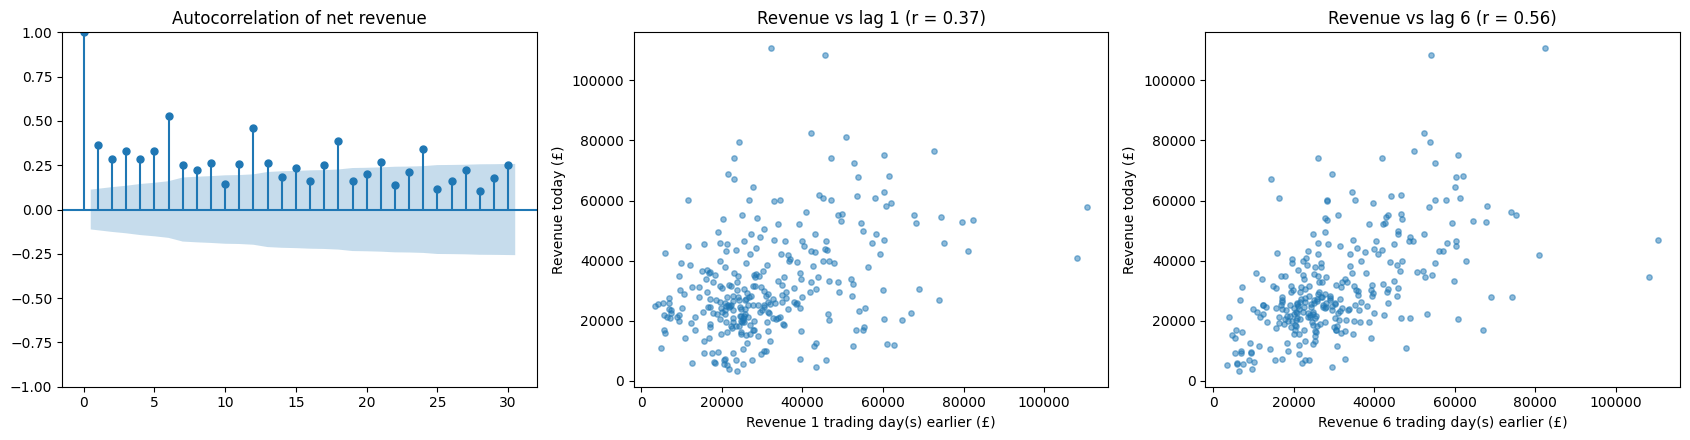

lag_1     0.368
lag_2     0.291
lag_3     0.341
lag_4     0.296
lag_5     0.345
lag_6     0.562
lag_7     0.268
lag_8     0.239
lag_9     0.283
lag_10    0.157
lag_11    0.278
lag_12    0.501
dtype: float64


In [47]:
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
plot_acf(rev, lags=30, ax=axes[0], title="Autocorrelation of net revenue")
for ax, lag in zip(axes[1:], [1, 6]):
    ax.scatter(rev.shift(lag), rev, alpha=0.5, s=15)
    ax.set_title(f"Revenue vs lag {lag} (r = {rev.autocorr(lag):.2f})")
    ax.set_xlabel(f"Revenue {lag} trading day(s) earlier (£)"); ax.set_ylabel("Revenue today (£)")
plt.tight_layout(); plt.savefig("outputs/figures/q2_lags.png"); plt.show()

print(pd.Series({f"lag_{k}": round(rev.autocorr(k), 3) for k in range(1, 13)}))

**Interpretation:** Revenue is clearly related to its past values, and the weekly relationship is stronger than the daily one. The correlation with the previous trading day (lag 1) is 0.37, while the correlation with the same weekday last week (lag 6) is 0.56. The ACF plot shows peaks at lags 6, 12, 18 and 24, multiples of the six-day trading week, which weaken gradually. Most lags up to 25 are statistically significant, reflecting the slow-moving trend found in Q1. Lags 1 and 6 (and possibly 12), together with rolling averages, should therefore be used as model features.

### Q3: Does revenue differ by day of the week?
Daily net revenue is grouped by weekday to check whether some trading days are consistently
stronger than others, which would explain the weekly peaks found in Q2.

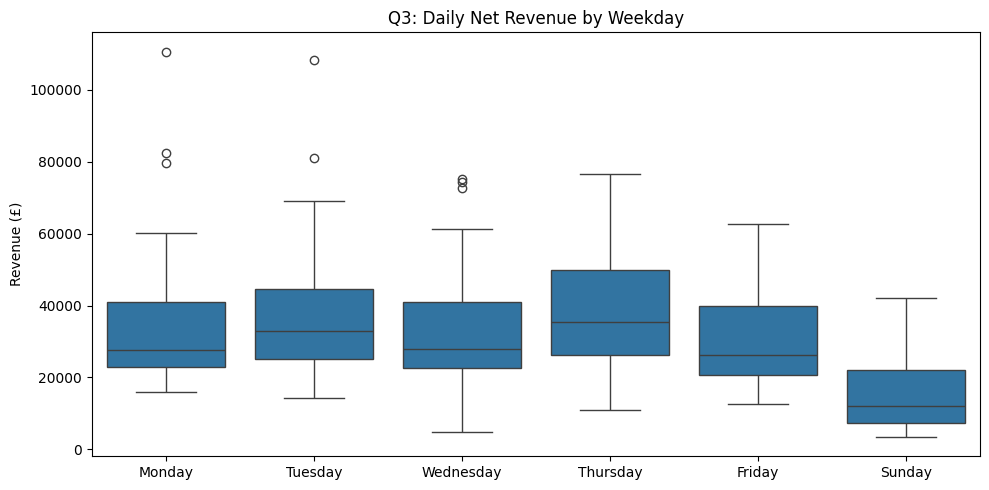

,mean,median,count
weekday,,,
Monday,34515.0,27770.0,47
Tuesday,37848.0,32981.0,52
Wednesday,32808.0,27834.0,53
Thursday,39254.0,35309.0,53
Friday,31457.0,26371.0,49
Sunday,15816.0,12194.0,50


In [48]:
import seaborn as sns
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Sunday"]
dow = daily.assign(weekday=daily.index.day_name())

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=dow, x="weekday", y="net_revenue", order=order, ax=ax)
ax.set_title("Q3: Daily Net Revenue by Weekday"); ax.set_ylabel("Revenue (£)"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig("outputs/figures/q3_weekday.png"); plt.show()

display(dow.groupby("weekday")["net_revenue"].agg(["mean", "median", "count"]).reindex(order).round(0))

**Interpretation:** Revenue varies clearly by weekday. Thursday is the strongest day (mean £39,254, median £35,309), followed by Tuesday (£37,848, median £32,981), while Monday, Wednesday and Friday sit in the middle (medians around £26,000–£28,000). Sunday is by far the weakest day, with a median of just £12,194, less than half of Thursday's, likely because wholesale business customers place fewer orders at weekends. On every weekday the mean is higher than the median, and Monday and Tuesday show outliers above £100,000, confirming that occasional very large orders skew the distribution. Monday has the fewest observations (47) because most UK bank holidays fall on Mondays. This weekly pattern explains the peaks at multiples of 6 in the Q2 autocorrelation plot, so the day of the week should be included as a model feature.

### Q4: Is daily revenue driven more by the number of orders or by order size?
Daily revenue can rise because more orders are placed or because each order is larger. A
correlation matrix of all daily variables is shown alongside scatter plots of revenue against
the number of invoices and the average basket value.

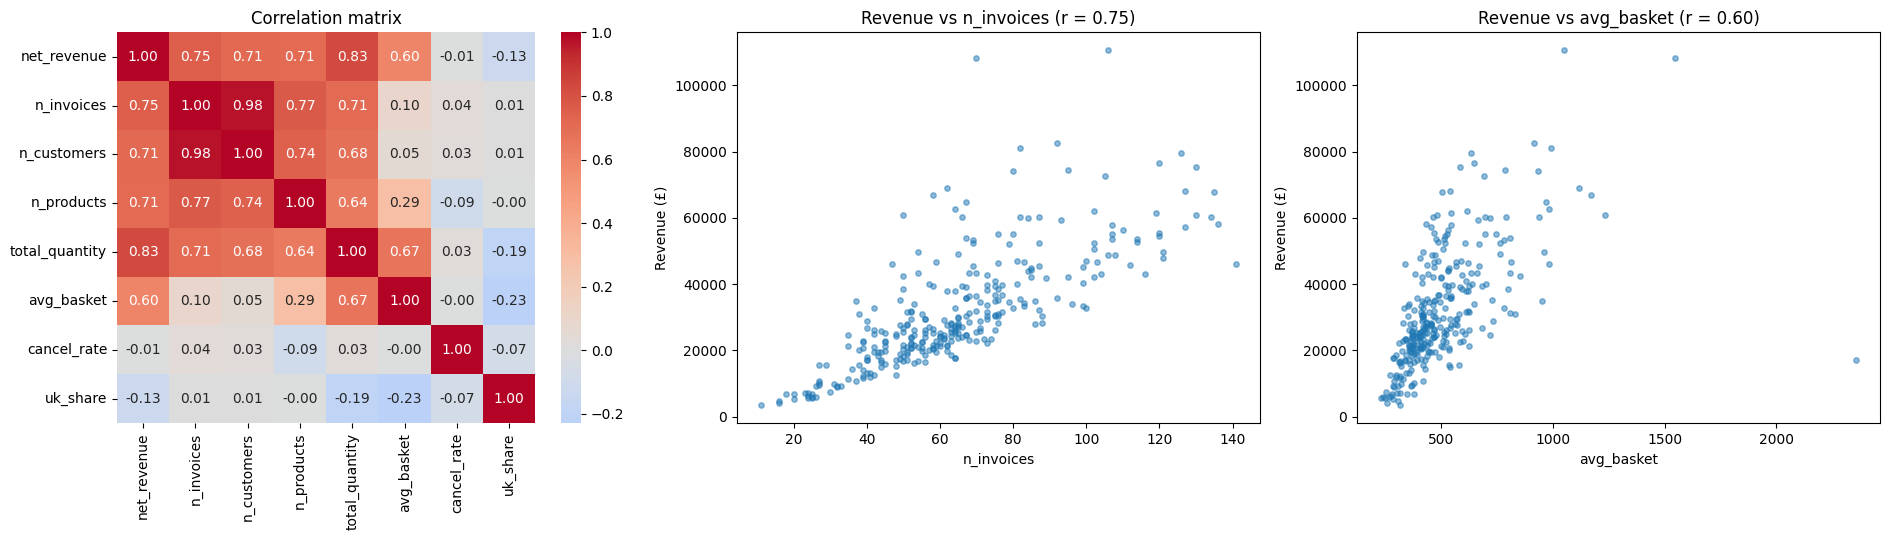

In [49]:
cols = ["net_revenue", "n_invoices", "n_customers", "n_products",
        "total_quantity", "avg_basket", "cancel_rate", "uk_share"]
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
sns.heatmap(daily[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Correlation matrix")
for ax, col in zip(axes[1:], ["n_invoices", "avg_basket"]):
    r = daily["net_revenue"].corr(daily[col])
    ax.scatter(daily[col], daily["net_revenue"], alpha=0.5, s=15)
    ax.set_title(f"Revenue vs {col} (r = {r:.2f})"); ax.set_xlabel(col); ax.set_ylabel("Revenue (£)")
plt.tight_layout(); plt.savefig("outputs/figures/q4_drivers.png"); plt.show()

**Interpretation:** Both the number of orders and order size drive revenue, and they act largely independently. Revenue correlates strongly with the number of invoices (r = 0.75) and moderately with the average basket value (r = 0.60), but these two drivers are almost uncorrelated with each other (r = 0.10): busy days do not necessarily have bigger orders. The number of orders gives a tighter, more consistent relationship, while basket size is more erratic, with a few very large orders producing outliers. Total quantity has the strongest correlation with revenue (0.83). The number of invoices and the number of customers are almost perfectly correlated (0.98), so they carry the same information, and using both as features would be redundant. Cancellation rate shows no relationship with revenue (−0.01), and UK share is weakly negative (−0.13), suggesting high-revenue days are slightly more often driven by international orders. Because these variables are only known at the end of the day, they cannot be used as same-day predictors; the model will use their lagged values instead, to avoid data leakage.

### Q5: Does the cancellation rate change over time?
The daily cancellation rate is plotted with a 30-day moving average, alongside the monthly
value of cancelled revenue, to check whether cancellations increase over time or during busy periods.

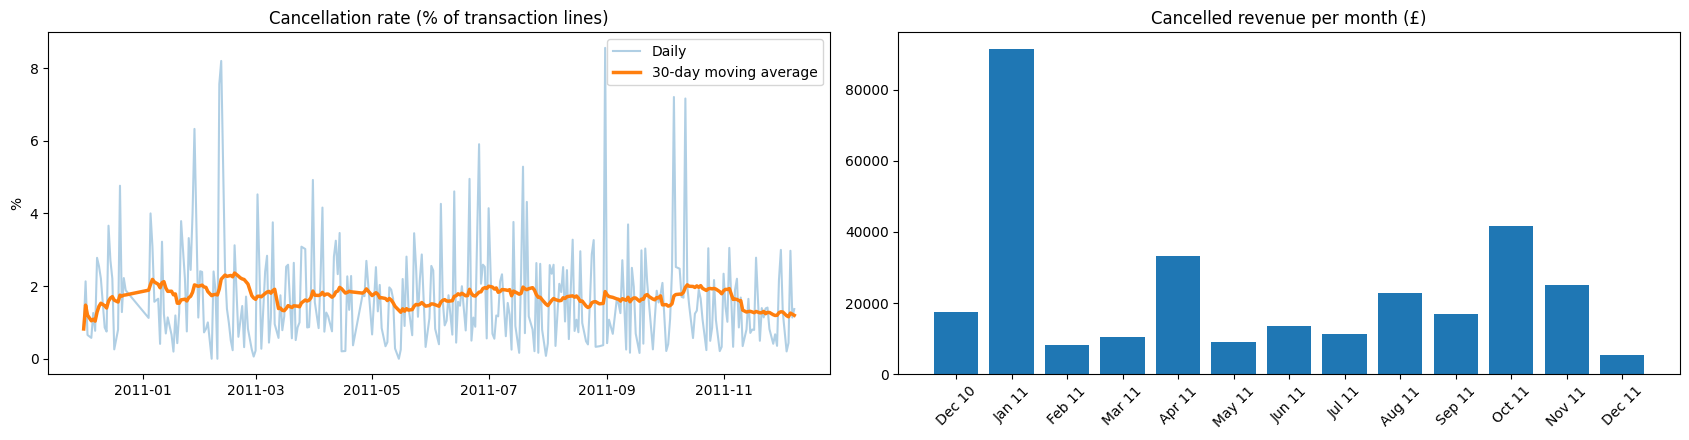

Cancelled revenue: £307,337 (3.1% of gross revenue)


In [50]:
cancelled_rev = daily["gross_revenue"] - daily["net_revenue"]
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
axes[0].plot(daily.index, daily["cancel_rate"] * 100, alpha=0.35, label="Daily")
axes[0].plot(daily.index, daily["cancel_rate"].rolling("30D").mean() * 100, linewidth=2.5, label="30-day moving average")
axes[0].set_title("Cancellation rate (% of transaction lines)"); axes[0].set_ylabel("%"); axes[0].legend()
monthly_cancel = cancelled_rev.resample("ME").sum()
axes[1].bar(monthly_cancel.index.strftime("%b %y"), monthly_cancel)
axes[1].set_title("Cancelled revenue per month (£)"); axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig("outputs/figures/q5_cancellations.png"); plt.show()

print(f"Cancelled revenue: £{cancelled_rev.sum():,.0f} ({cancelled_rev.sum() / daily['gross_revenue'].sum():.1%} of gross revenue)")

**Interpretation:** The cancellation rate is stable over time and shows no clear trend. Its 30-day moving average stays between about 1.2% and 2.3% of transaction lines throughout the year, although individual days occasionally spike to around 8%. In total, cancellations removed £307,337, about 3.1% of gross revenue. In monetary terms, January 2011 stands out with over £90,000 of cancelled revenue, but most of this comes from the single cancelled order of 74,215 storage jars identified in Section 3.3, so it reflects one data-entry event rather than a pattern. Cancelled revenue is also higher in April and October, but because the rate itself stays flat, this mostly reflects higher sales volumes rather than customers cancelling more often. The rate is actually slightly lower in the busy November–December period. This agrees with Q4, where cancellation rate showed no correlation with revenue (−0.01), so it is unlikely to be a useful predictor. Since net revenue already accounts for cancellations, they do not need to be modeled separately.

### Q6: Does the UK's share of revenue change across the year?
The UK's share of monthly revenue is calculated, and the largest international markets are compared,
to see whether the series is becoming more or less dependent on UK customers.

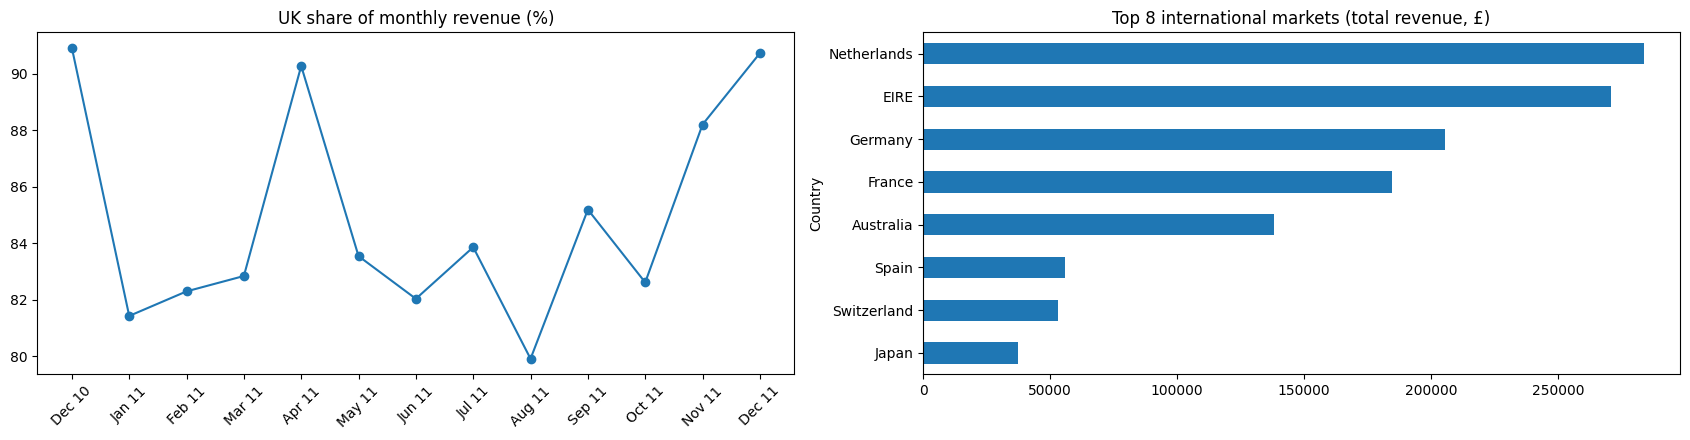

,uk_share_%
date,
2010-12-31,90.9
2011-01-31,81.4
2011-02-28,82.3
2011-03-31,82.8
2011-04-30,90.3
2011-05-31,83.5
2011-06-30,82.0
2011-07-31,83.9
2011-08-31,79.9


In [51]:
uk_rev = daily["uk_share"] * daily["gross_revenue"]
monthly_uk = (uk_rev.resample("ME").sum() / daily["gross_revenue"].resample("ME").sum()) * 100
intl = (clean_df[(~clean_df["is_cancelled"]) & (clean_df["Country"] != "United Kingdom")]
        .groupby("Country")["Revenue"].sum().nlargest(8))

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
axes[0].plot(monthly_uk.index.strftime("%b %y"), monthly_uk, marker="o")
axes[0].set_title("UK share of monthly revenue (%)"); axes[0].tick_params(axis="x", rotation=45)
intl.sort_values().plot.barh(ax=axes[1], title="Top 8 international markets (total revenue, £)")
plt.tight_layout(); plt.savefig("outputs/figures/q6_geography.png"); plt.show()
display(monthly_uk.round(1).to_frame("uk_share_%"))

**Interpretation:** The UK consistently generates the large majority of revenue, between about 80% and 91% each month. Its share is highest in December 2010, April 2011 and December 2011 (around 90–91%), and lowest in August 2011 (about 80%). The rise in the UK share from October to December suggests that the pre-Christmas increase in revenue seen in Q1 is driven mainly by UK customers rather than international ones. Among international markets, the Netherlands generates the most revenue (about £285,000), followed by EIRE (about £270,000), Germany (about £205,000), France (about £185,000) and Australia (about £138,000). The Netherlands ranks first by revenue even though Germany and France have more transaction lines (Section 2.4), which suggests that Dutch customers place fewer but much larger wholesale orders. Because international revenue makes up only 10–20% of the total and its share changes gradually, the series mainly reflects UK demand, and geography is expected to add little predictive value.

## Step 6: Feature Engineering
Features are created based on the findings in Step 5. Every feature for day *t* uses only
information available before day *t*: lags and rolling statistics are shifted by one day, so the
value being predicted is never included in its own features (preventing data leakage). Rolling
windows count trading days, so a 6-day window covers one trading week.

In [52]:
TARGET = "net_revenue"

def make_features(daily):
    f = daily.copy()
    rev = f[TARGET]
    for k in [1, 2, 6, 12]:                        # Q2: daily and weekly lags
        f[f"lag_{k}"] = rev.shift(k)
    f["roll_mean_6"] = rev.shift(1).rolling(6).mean()     # Q1: recent level (1 week)
    f["roll_mean_24"] = rev.shift(1).rolling(24).mean()   # Q1: longer-term level (~1 month)
    f["roll_std_6"] = rev.shift(1).rolling(6).std()       # recent volatility
    f["invoices_lag_1"] = f["n_invoices"].shift(1)        # Q4: drivers, lagged
    f["basket_lag_1"] = f["avg_basket"].shift(1)
    f["dow"] = f.index.dayofweek                          # Q3: weekday effect
    f["days_since_last"] = f.index.to_series().diff().dt.days  # gap after weekends/holidays
    return f.dropna()

FEATURES = ["lag_1", "lag_2", "lag_6", "lag_12", "roll_mean_6", "roll_mean_24",
            "roll_std_6", "invoices_lag_1", "basket_lag_1", "dow", "days_since_last"]

features = make_features(daily)
print(features.shape)
display(features[FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(ascending=False).round(3))

(280, 20)


,net_revenue
lag_6,0.577
roll_mean_6,0.567
roll_mean_24,0.556
lag_12,0.532
invoices_lag_1,0.460
lag_1,0.367
lag_2,0.302
roll_std_6,0.269
basket_lag_1,0.048
dow,-0.342


**Observations:** Feature engineering produced 280 rows and 11 features; 24 rows were lost because the 24-day rolling average needs a full window. The highest correlation with the target is 0.577, so there is no sign of data leakage. As found in Q1 and Q2, the strongest predictors are `lag_6` (0.58) and the 6- and 24-day rolling averages (0.57 and 0.56). Yesterday's invoice count (0.46) predicts better than yesterday's revenue (0.37), while yesterday's basket size adds almost nothing (0.05). The weekday effect is non-linear, so it is one-hot encoded for linear models.

## Step 7: Model Training and Experiments
The data is split chronologically: the first 80% of days are used for training and the last 20%
for testing, so the model is always evaluated on future data it has not seen. Two simple baselines
are used as reference points, then linear and Random Forest models are trained. Hyperparameters are
tuned with time-series cross-validation (`TimeSeriesSplit`), where each validation fold comes after
its training data, avoiding look-ahead bias. Models are compared using MAE, RMSE and MAPE.

### 7.1 Chronological split

In [53]:
split = int(len(features) * 0.8)
train, test = features.iloc[:split], features.iloc[split:]
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print(f"Train: {train.index.min().date()} to {train.index.max().date()} ({len(train)} days)")
print(f"Test:  {test.index.min().date()} to {test.index.max().date()} ({len(test)} days)")

Train: 2011-01-09 to 2011-10-04 (224 days)
Test:  2011-10-05 to 2011-12-08 (56 days)


**Observations:** The data is split chronologically into 224 training days (9 January to 4 October 2011) and 56 test days (5 October to 8 December 2011). The test period covers the pre-Christmas peak, when revenue is higher than anything in most of the training data, which makes it a demanding but realistic test of forecasting ability.

### 7.2 Evaluation helper and baselines

In [54]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

results = []
def evaluate(name, y_pred, params="-"):
    results.append({"Experiment": name, "Key parameters": params,
                    "MAE": mean_absolute_error(y_test, y_pred),
                    "RMSE": mean_squared_error(y_test, y_pred) ** 0.5,
                    "MAPE (%)": mean_absolute_percentage_error(y_test, y_pred) * 100})

evaluate("Baseline: naive (lag 1)", test["lag_1"])
evaluate("Baseline: seasonal naive (lag 6)", test["lag_6"])

### 7.3 Linear models

In [55]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV

num_cols = [c for c in FEATURES if c != "dow"]
def preprocessor():
    return make_column_transformer((OneHotEncoder(handle_unknown="ignore"), ["dow"]),
                                   (StandardScaler(), num_cols))
tscv = TimeSeriesSplit(n_splits=5)

lin = make_pipeline(preprocessor(), LinearRegression()).fit(X_train, y_train)
evaluate("Linear Regression", lin.predict(X_test))

ridge_search = GridSearchCV(make_pipeline(preprocessor(), Ridge()),
                            {"ridge__alpha": [0.01, 0.1, 1, 10, 50, 100, 300]},
                            cv=tscv, scoring="neg_mean_absolute_error").fit(X_train, y_train)
evaluate("Ridge (tuned)", ridge_search.predict(X_test), f"alpha={ridge_search.best_params_['ridge__alpha']}")

### 7.4 Random Forest

In [56]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(random_state=42).fit(X_train, y_train)
evaluate("Random Forest (default)", rf.predict(X_test), "n_estimators=100, max_depth=None")

rf_grid = {"n_estimators": [100, 300, 500], "max_depth": [3, 5, 8, None],
           "min_samples_leaf": [1, 3, 5, 10], "max_features": ["sqrt", 0.5, 1.0]}
rf_search = RandomizedSearchCV(RandomForestRegressor(random_state=42), rf_grid, n_iter=30,
                               cv=tscv, scoring="neg_mean_absolute_error",
                               random_state=42, n_jobs=-1).fit(X_train, y_train)
evaluate("Random Forest (tuned)", rf_search.predict(X_test), str(rf_search.best_params_))

### 7.5 Experiment table

In [57]:
results_df = pd.DataFrame(results).round(2)
pd.set_option("display.max_colwidth", None)
display(results_df)

,Experiment,Key parameters,MAE,RMSE,MAPE (%)
0,Baseline: naive (lag 1),-,18118.62,24022.36,48.09
1,Baseline: seasonal naive (lag 6),-,13860.01,18126.92,30.15
2,Linear Regression,-,11072.58,15228.83,25.53
3,Ridge (tuned),alpha=50,11597.13,15744.61,25.70
4,Random Forest (default),"n_estimators=100, max_depth=None",12851.67,16860.35,25.87
5,Random Forest (tuned),"{'n_estimators': 100, 'min_samples_leaf': 3, 'max_features': 1.0, 'max_depth': 3}",13893.13,18608.54,26.44


**Observations:** All models outperform both baselines. The seasonal naive baseline (MAE £13,860) is much better than the naive one (£18,119), confirming the weekly pattern found in Q2. Linear Regression performs best, with an MAE of £11,073, about 20% lower than the seasonal naive baseline and 39% lower than the naive one. Tuning did not improve test performance: tuned Ridge (alpha = 50) and the tuned Random Forest scored slightly worse than their untuned versions. Tuning optimizes accuracy on earlier time periods, which differ from the higher-revenue test period. Random Forest performs worst among the models because it cannot predict values above those seen in training, which matters during the peak. A MAPE of about 25% remains fairly high, reflecting how volatile daily revenue is and the unpredictable very large orders.

### 7.6 Forecast vs Actual
The best model's test predictions are plotted against actual revenue to show where it succeeds and fails.

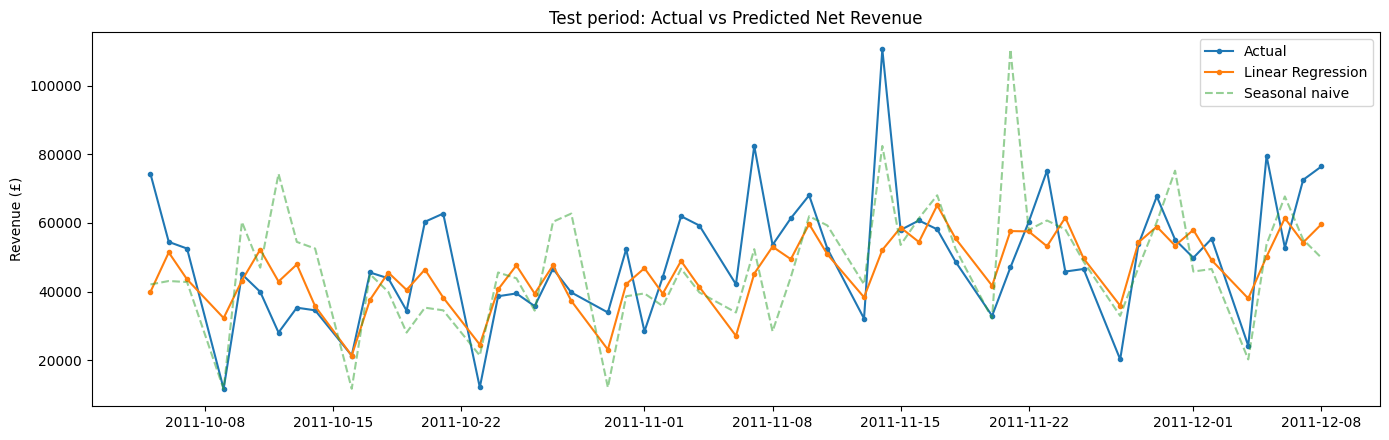

In [58]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(y_test.index, y_test, label="Actual", marker="o", markersize=3)
ax.plot(y_test.index, lin.predict(X_test), label="Linear Regression", marker="o", markersize=3)
ax.plot(y_test.index, test["lag_6"], label="Seasonal naive", alpha=0.5, linestyle="--")
ax.set_title("Test period: Actual vs Predicted Net Revenue"); ax.set_ylabel("Revenue (£)"); ax.legend()
plt.tight_layout(); plt.savefig("outputs/figures/forecast_vs_actual.png"); plt.show()

**Observations:** Linear Regression follows the weekly ups and downs and the rising level of the test period closely, but its forecasts are smoother than actual revenue. It misses the most extreme days, such as about £110,000 on 14 November (predicted about £52,000) and about £82,000 on 7 November, which are driven by unusually large orders that no feature can anticipate. The seasonal naive baseline shows why the model performs better: it simply copies last week's values, so the 14 November spike reappears as a false spike a week later, whereas the regression averages several features and avoids this. The model also underpredicts the final days of December, consistent with the rising pre-Christmas level found in Q1.

### 7.7 Saving the Final Model
Linear Regression is selected as the final model. It is refitted on all available data (training and test) so
that it uses the most recent revenue levels, then saved with its feature list for use in the
prediction script (Task 4). The saved pipeline includes the one-hot encoding and scaling steps.

In [59]:
import joblib, json
os.makedirs("models", exist_ok=True)

final_model = make_pipeline(preprocessor(), LinearRegression()).fit(features[FEATURES], features[TARGET])
joblib.dump(final_model, "models/best_model.pkl")
with open("models/model_config.json", "w") as f:
    json.dump({"features": FEATURES, "target": TARGET, "model": "LinearRegression"}, f, indent=2)
print("Saved model and config")

Saved model and config


## Step 8: Reusable Preprocessing Module
The cleaning, aggregation and feature functions are saved as `src/preprocessing.py`, so the
prediction script (Task 4) applies exactly the same pipeline used to train the model.

In [60]:
os.makedirs("src", exist_ok=True)

In [61]:
%%writefile src/preprocessing.py
"""Preprocessing pipeline for the Online Retail daily revenue forecast (Task 1).
Used by the prediction script (Task 4) to apply the same steps as model training."""
import pandas as pd

TARGET = "net_revenue"
NON_PRODUCT_CODES = ["POST", "DOT", "C2", "M", "D", "S", "B", "BANK CHARGES", "AMAZONFEE", "CRUK"]
FEATURES = ["lag_1", "lag_2", "lag_6", "lag_12", "roll_mean_6", "roll_mean_24",
            "roll_std_6", "invoices_lag_1", "basket_lag_1", "dow", "days_since_last"]


def clean_transactions(df):
    """Remove duplicates, non-products and invalid prices; flag cancellations; add Revenue."""
    df = df.copy()
    df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
    df["InvoiceNo"] = df["InvoiceNo"].astype(str)
    df["StockCode"] = df["StockCode"].astype(str)
    df = df.drop_duplicates()
    df = df[~df["StockCode"].str.upper().isin(NON_PRODUCT_CODES)]
    df = df[~df["StockCode"].str.lower().str.startswith("gift_")]
    df = df[df["UnitPrice"] > 0]
    df["is_cancelled"] = df["InvoiceNo"].str.startswith("C")
    df = df[(df["Quantity"] > 0) | df["is_cancelled"]]
    df["CustomerID"] = df["CustomerID"].astype("string").fillna("UNKNOWN")
    df["Revenue"] = df["Quantity"] * df["UnitPrice"]
    return df


def aggregate_daily(df):
    """Aggregate cleaned transactions into one row per trading day."""
    df = df.copy()
    df["date"] = df["InvoiceDate"].dt.normalize()
    sales = df[~df["is_cancelled"]]
    daily = sales.groupby("date").agg(
        gross_revenue=("Revenue", "sum"), n_invoices=("InvoiceNo", "nunique"),
        n_products=("StockCode", "nunique"), total_quantity=("Quantity", "sum"))
    known = sales[sales["CustomerID"] != "UNKNOWN"]
    daily["n_customers"] = known.groupby("date")["CustomerID"].nunique()
    daily["net_revenue"] = df.groupby("date")["Revenue"].sum()
    daily["cancel_rate"] = df.groupby("date")["is_cancelled"].mean()
    daily["avg_basket"] = daily["gross_revenue"] / daily["n_invoices"]
    uk = sales[sales["Country"] == "United Kingdom"].groupby("date")["Revenue"].sum()
    daily["uk_share"] = uk / daily["gross_revenue"]
    return daily.fillna(0)


def make_features(daily):
    """Create lag, rolling and calendar features using only past information."""
    f = daily.copy()
    rev = f[TARGET]
    for k in [1, 2, 6, 12]:
        f[f"lag_{k}"] = rev.shift(k)
    f["roll_mean_6"] = rev.shift(1).rolling(6).mean()
    f["roll_mean_24"] = rev.shift(1).rolling(24).mean()
    f["roll_std_6"] = rev.shift(1).rolling(6).std()
    f["invoices_lag_1"] = f["n_invoices"].shift(1)
    f["basket_lag_1"] = f["avg_basket"].shift(1)
    f["dow"] = f.index.dayofweek
    f["days_since_last"] = f.index.to_series().diff().dt.days
    return f.dropna()

Overwriting src/preprocessing.py


In [62]:
import sys; sys.path.append(".")
from src.preprocessing import clean_transactions as ct, aggregate_daily as ad, make_features as mf

check = mf(ad(ct(df))).loc[lambda x: x.index < "2011-12-09"]
print("Module output matches notebook:", check[FEATURES].equals(features[FEATURES]))

Module output matches notebook: True
